# Лабораторная работа №1 - классический NLP (Jeopardy!)

Интерактивная версия конвейера из пакета `lab1` (headless-аналог: `uv run python -m lab1.source.main`).

- Ядро: **Python (nlp)** - общее uv-окружение проекта.
- Запуск GUI: `uv run jupyter lab lab1/lab1.ipynb` из корня проекта.
- Полный прогон headless (все ячейки исполнятся, выводы встроются):
  `uv run python -m jupyter nbconvert --to notebook --execute --inplace lab1/lab1.ipynb --ExecutePreprocessor.kernel_name=nlp-lab1 --ExecutePreprocessor.timeout=900`

Отчёт с формулами и сводными таблицами: [README.md](../README.md).

In [1]:
import math, re, sys, time
from collections import Counter
from pathlib import Path

# ядро Jupyter стартует из lab1/ -> добавляем корень проекта в sys.path
ROOT = Path.cwd().parent if Path.cwd().name == "lab1" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from lab1.source.source.data import load_and_split
from lab1.source.source.clean import audit_noise, clean_and_tokenize, clean_text
from lab1.source.source.normalize import normalize_methods
from lab1.source.source.levenshtein import levenshtein, find_typo_pairs
from lab1.source.source.lm import NgramLM, UNKN, generate, perplexity, prob_addk, prob_raw, prob_stupid, prob_unigram

%matplotlib inline
plt.rcParams["figure.figsize"] = (11, 4)
print("готово: модули lab1 импортированы")

готово: модули lab1 импортированы


## Пункт 1 - загрузка и сплит 80/20 (стратификация по `Round`)

Целевая колонка - `Question`. Последнее выражение ячейки - таблица первых 5 строк train.

In [2]:
t0 = time.time()
train, test = load_and_split()
print(f"время ячейки: {time.time() - t0:.1f} c")
train.head(5)

[1] Всего документов: 216930
    Train: 173544  Test: 43386  (80/20, stratify=Round)
    Классы Round (train): {'Jeopardy!': 85907, 'Double Jeopardy!': 84730, 'Final Jeopardy!': 2905, 'Tiebreaker': 2}
время ячейки: 0.3 c


,Show Number,Air Date,Round,Category,Value,Question,Answer
71430,5235,2007-05-18,Jeopardy!,"""HIT""TING",$400,"As a verb, ""thumb"" is a synonym for this",hitchhiking
110783,4823,2005-07-20,Jeopardy!,DISNEY SONG LYRICS,$800,"""Les poissons, Les poissons How I love Les poi...",The Little Mermaid
32561,5657,2009-03-24,Double Jeopardy!,A VISIT TO BROOKHAVEN NATIONAL LABORATORY,$800,"(<a href=""http://www.j-archive.com/media/2009-...",the Big Bang
31783,4305,2003-04-25,Jeopardy!,AN ANCIENT LIFETIME AGO,$800,"Ptolemy X, a little short of funds, replaced t...",Alexander the Great
189293,5752,2009-09-22,Double Jeopardy!,THE NATIONAL BOOK AWARDS,$1600,"This southerner won 2 of the first 6 awards, f...",Faulkner


## Пункт 2 - EDA на train

Распределение длин (слова/символы) и топ-30 стоп-слов NLTK.

документов: 173544
средняя длина: 17.49 слов, 86.22 символов


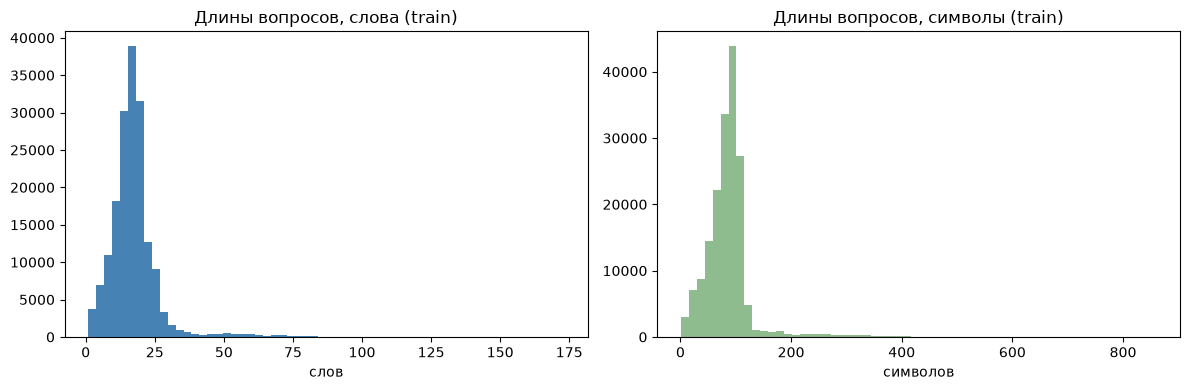

In [3]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

texts = train["Question"].astype(str)
n_words = [len(word_tokenize(t)) for t in texts]
n_chars = [len(t) for t in texts]
print(f"документов: {len(texts)}")
print(f"средняя длина: {sum(n_words)/len(n_words):.2f} слов, {sum(n_chars)/len(n_chars):.2f} символов")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(n_words, bins=60, color="steelblue")
axes[0].set_title("Длины вопросов, слова (train)")
axes[0].set_xlabel("слов")
axes[1].hist(n_chars, bins=60, color="darkseagreen")
axes[1].set_title("Длины вопросов, символы (train)")
axes[1].set_xlabel("символов")
fig.tight_layout()
plt.show()

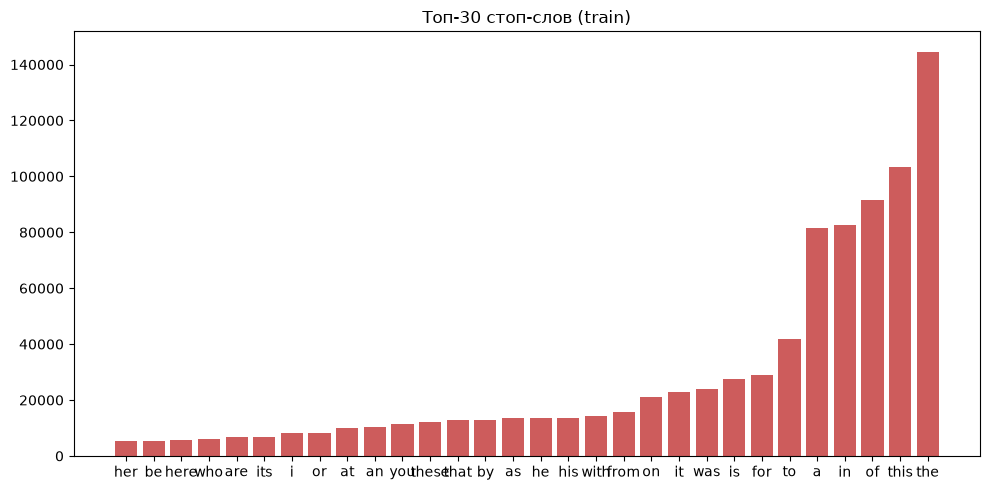

топ-10: [('the', 144651), ('this', 103308), ('of', 91653), ('in', 82559), ('a', 81437), ('to', 41872), ('for', 29027), ('is', 27695), ('was', 23815), ('it', 22934)]


In [4]:
sw = set(stopwords.words("english"))
cnt = Counter()
for t in texts:
    cnt.update(w.lower() for w in word_tokenize(t) if w.lower() in sw)
top = cnt.most_common(30)
words = [w for w, _ in top][::-1]
counts = [c for _, c in top][::-1]
plt.figure(figsize=(10, 5))
plt.bar(words, counts, color="indianred")
plt.title("Топ-30 стоп-слов (train)")
plt.tight_layout()
plt.show()
print("топ-10:", top[:10])

## Пункт 3 - аудит доменных шумов

`audit_noise` считает затронутые документы и вхождения по regex-шаблону; ниже - живые примеры корпуса по каждому типу.

In [5]:
audit_noise(train)

[3] Аудит шума в корпусе (train):
          html_tags: в 8576 документах (4.9%), вхождений 21819
      html_entities: в 25 документах (0.0%), вхождений 38
               urls: в 8504 документах (4.9%), вхождений 10462


      numbers_money: в 73609 документах (42.4%), вхождений 137144


          emoticons: в 9754 документах (5.6%), вхождений 11769
      smart_unicode: в 442 документах (0.3%), вхождений 955
        multi_punct: в 3123 документах (1.8%), вхождений 3408


{'html_tags': (8576, 21819),
 'html_entities': (25, 38),
 'urls': (8504, 10462),
 'numbers_money': (73609, 137144),
 'emoticons': (9754, 11769),
 'smart_unicode': (442, 955),
 'multi_punct': (3123, 3408)}

In [6]:
examples = []
patterns = [(r"<b>|<br", "html-теги"), (r"http", "url"), (r"\$\d", "числа/деньги"),
            (r":-|>:\(", "смайлики"), (r"\.\.\.|!!!|\?\?\?", "повторная пунктуация")]
for pat, tag in patterns:
    q = train.loc[train["Question"].str.contains(pat, regex=True, na=False), "Question"].iloc[0]
    examples.append((tag, q[:150]))
pd.DataFrame(examples, columns=["тип шума", "пример из корпуса (train)"])

,тип шума,пример из корпуса (train)
0,html-теги,"<a href=""http://www.j-archive.com/media/2010-0..."
1,url,"(<a href=""http://www.j-archive.com/media/2009-..."
2,числа/деньги,"Frank was paid $8,000 to play Maggio in this 1..."
3,смайлики,:-b.. Doing this means either you're hungry or...
4,повторная пунктуация,"In the film ""Maverick"", he has a cameo, almost..."


## Пункт 4 - чистка и токенизация

Правила конвейера: `&amp;→&`, HTML-теги→пробел, URL→`[URL]`, смайлики→`[EMOJI]`,
числа/деньги→`[NUM]`, smart-кавычки→ASCII, `!!!`/`???`/`...`→`[ELLIPSIS]`, сентинели `<s> … </s>`.

In [7]:
raw = train.loc[train["Question"].str.contains(r"<b>|<br|http", regex=True, na=False), "Question"].iloc[0]
cleaned = clean_text(raw)
pd.DataFrame([{"было": raw[:180], "стало": cleaned[:180]}], index=["пример"])

,было,стало
пример,"(<a href=""http://www.j-archive.com/media/2009-...",<s> [URL] Kelly of the Clue Crew reports from ...


In [8]:
t0 = time.time()
tr_docs, te_docs = clean_and_tokenize(train, test)
print(f"токенов train: {sum(len(d) for d in tr_docs)}, test: {sum(len(d) for d in te_docs)}  ({time.time()-t0:.1f} c)")
tr_docs[0][:22]

[4] Очистка завершена; пример: <s> As a verb "thumb" is a synonym for this </s> ...
токенов train: 2851278, test: 710483  (1.4 c)


['<s>',
 'As',
 'a',
 'verb',
 '"thumb"',
 'is',
 'a',
 'synonym',
 'for',
 'this',
 '</s>']

## Пункт 5 - стемминг против лемматизации

Сравнение размеров словаря корпуса + наглядные пары (стем против леммы с POS-тегом).

In [9]:
t0 = time.time()
_ = normalize_methods(tr_docs)
print(f"время (pos_tag + леммы на корпусе): {time.time() - t0:.1f} c")

[5] Нормализация (уникальные токены словаря):
    без нормализации : 125833
    PorterStemmer    : 106074 (-15.7%)
    WordNetLemmatizer: 116167 (-7.7%)
время (pos_tag + леммы на корпусе): 35.2 c


In [10]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tag import pos_tag
from lab1.source.normalize import WN_POS

stemmer, lemmatizer = PorterStemmer(), WordNetLemmatizer()
rows = []
for w in ["running", "studies", "better", "cities", "wrote", "dishes"]:
    tag = pos_tag([w])[0][1]
    pos = WN_POS.get(tag[0])
    lem = lemmatizer.lemmatize(w, pos) if pos else lemmatizer.lemmatize(w)
    rows.append((w, tag, stemmer.stem(w), lem))
pd.DataFrame(rows, columns=["слово", "POS", "PorterStemmer", "лемма (WordNet)"])

,слово,POS,PorterStemmer,лемма (WordNet)
0,running,VBG,run,run
1,studies,NNS,studi,study
2,better,RBR,better,well
3,cities,NNS,citi,city
4,wrote,VBD,wrote,write
5,dishes,NNS,dish,dish


## Пункт 6 - расстояние Левенштейна 

$D_{i,j} = \min(D_{i-1,j}+1,\ D_{i,j-1}+1,\ D_{i-1,j-1}+(a_i \neq b_j))$

Самопроверка + поиск пар частотных слов с d=1..2.

In [11]:
print("levenshtein('kitten', 'sitting') =", levenshtein("kitten", "sitting"))
print("levenshtein('the', 'her')        =", levenshtein("the", "her"))
pairs, freq = find_typo_pairs(tr_docs)

levenshtein('kitten', 'sitting') = 3
levenshtein('the', 'her')        = 2


[6] Пары слов с dist=1: 424, с dist=2: 3745 (перебор по 800 самым частотным словам)
    Топ-10 (dist=1):
      this <-> his  (freq 102916x13583)
      the <-> she  (freq 136930x3858)
      the <-> they  (freq 136930x1846)
      the <-> them  (freq 136930x1299)
      was <-> has  (freq 23348x4830)
      the <-> then  (freq 136930x680)
      his <-> has  (freq 13583x4830)
      was <-> war  (freq 23348x1865)
      name <-> named  (freq 8976x4503)
      his <-> him  (freq 13583x2472)
    Топ-10 (dist=2):
      the <-> this  (freq 136930x102916)
      the <-> these  (freq 136930x11957)
      the <-> that  (freq 136930x11412)
      the <-> one  (freq 136930x9986)
      this <-> these  (freq 102916x11957)
      this <-> that  (freq 102916x11412)
      the <-> are  (freq 136930x6687)
      the <-> who  (freq 136930x5621)
      the <-> her  (freq 136930x5111)
      the <-> when  (freq 136930x4932)


## Пункт 7 - триграммная модель с `[UNK]`

$P(w_3 \mid w_1 w_2) = c(w_1 w_2 w_3)\, /\, c(w_1 w_2)$. Словарь train + токен `[UNK]` для OOV test-слов.

In [12]:
t0 = time.time()
lm = NgramLM(tr_docs, n=3)
print(f"построение LM: {time.time() - t0:.1f} c")
print(f"N={lm.n}, словарь={len(lm.vocab)}, токенов train={lm.n_tokens}")

te_docs_oov = [lm.map_oov(d) for d in te_docs]
oov_tokens = sum(w == UNKN for d in te_docs_oov for w in d)
print(f"OOV [UNK] в test: {oov_tokens} из {sum(len(d) for d in te_docs_oov)}")
[w for w in te_docs[0] if w not in lm.vocab][:12]

построение LM: 2.1 c
N=3, словарь=146021, токенов train=2851278
OOV [UNK] в test: 19931 из 710483


["McTear's", 'Dalmore']

## Пункт 8 - сглаживание и перплексия

$\mathrm{PPL} = 2^{-\frac{1}{N}\sum_i \log_2 P(w_i \mid w_1 w_2)}$

Add-k: $P = \frac{c(w_1w_2w_3)+k}{c(w_1w_2)+kV}$; stupid backoff (Ney et al., 2004): при $c=0$ - $\alpha P(w_3|w_2)$, рекурсивно до unigram.

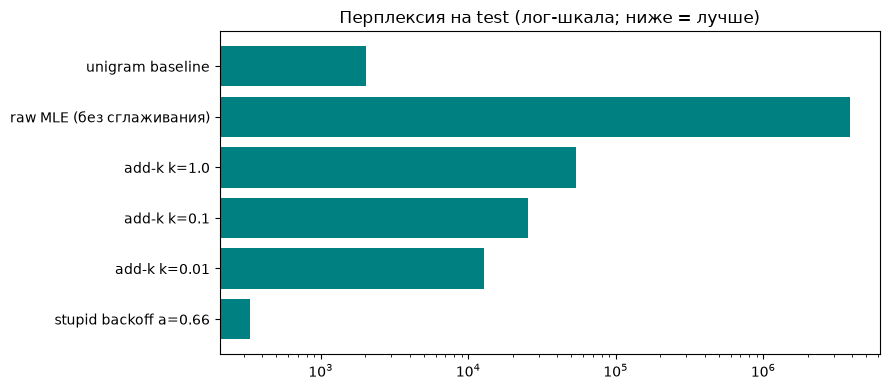

,модель,PPL (test),нулевых событий,"время, c"
0,unigram baseline,2015.39,0/623711,0.1
1,raw MLE (без сглаживания),3869756.31,384162/623711,0.8
2,add-k k=1.0,53373.73,0/623711,0.7
3,add-k k=0.1,25247.34,0/623711,0.8
4,add-k k=0.01,12783.92,0/623711,0.8
5,stupid backoff a=0.66,329.63,0/623711,2.9


In [13]:
rows = [
    ("unigram baseline", prob_unigram),
    ("raw MLE (без сглаживания)", prob_raw),
    ("add-k k=1.0", prob_addk),
    ("add-k k=0.1", lambda *a: prob_addk(*a, k=0.1)),
    ("add-k k=0.01", lambda *a: prob_addk(*a, k=0.01)),
    ("stupid backoff a=0.66", prob_stupid),
]
res = []
for name, fn in rows:
    t0 = time.time()
    ppl, zeros, n = perplexity(lm, te_docs_oov, fn)
    res.append((name, round(ppl, 2), f"{zeros}/{n}", round(time.time() - t0, 1)))
res_df = pd.DataFrame(res, columns=["модель", "PPL (test)", "нулевых событий", "время, c"])

plt.figure(figsize=(9, 4))
plt.barh(res_df["модель"], res_df["PPL (test)"], log=True, color="teal")
plt.gca().invert_yaxis()
plt.title("Перплексия на test (лог-шкала; ниже = лучше)")
plt.tight_layout()
plt.show()
res_df

## Пункт 9 - генерация марковской цепью

Старт `<s> <s>`, шаг по $P(\cdot\mid w_1 w_2)$ с backoff bigram→unigram, стоп `</s>`/max_len=30.

In [14]:
texts = generate(lm, n_texts=5, max_len=30, seed=42)
for i, t in enumerate(texts, 1):
    print(f"{i}. {t}")

1. Sit by the Iroquois the "Three Tenors" played the Acid Queen in "Tommy" Aunty Entity in "Mad Max [NUM] " tall [URL] he's been the first Italian-American to sit on
2. This novelist is the hardest substance in the sand it can also buy apple butter cake pie [NUM] feet high it lays an egg on top is made from jute
3. [URL] Kelly of the only president inaugurated in Washington D.C. President Harding unveiled a statue of this dog called "Yorkie" for short provides support for a young male attendant at
4. Among the most from any other woman his wife the Chapel of the Year" award went to Washington also served on crackers it's a title playing on golf's senior tour
5. There are no match for a 1920s play about this biblical book with this Great Lake [NUM] [NUM] the Defense Secretary of State under Truman he represented it as a


## Выводы

- MLE без сглаживания проваливается (61.7% unseen-контекстов → P=0, PPL ≈ 4·10⁶).
- Add-k при V=146K размывает массу (PPL 13–54K); **stupid backoff - лучший: 331**, в 6 раз ниже unigram-бейслайна (2 014) → модель реально использует контекст.
- Стемминг сжимает словарь сильнее (−15.7% против −7.7% у лемматизации), лемматизация даёт настоящие слова.
- Генерация: локальная связность (клише жанра) при глобальной несвязности - профиль сырой марковской цепи.
